# Sensor Reconstruction using a Masked Graph Autoencoder

## Objective

The objective of this project is to reconstruct the value of a missing vibration sensor using the measurements of the remaining sensors **at the same timestamp**.

Unlike conventional time-series forecasting methods such as LSTMs or ARIMA, this approach **does not use historical observations**. Each timestamp is treated as an independent sample because vibration events can be highly irregular and unpredictable.

Instead of learning temporal dependencies, the model learns the **relationships between sensors** represented as a graph.

## Why a Graph Neural Network?

Traditional machine learning models consider the input as a simple feature vector:

$$ x = [x_1,x_2,\ldots,x_n] $$

where every feature is treated independently.

However, industrial sensors are physically connected.

For example,

Motor → Pump → Pressure → Temperature

Changes in one component influence the others through the physical behavior of the machine.

Graph Neural Networks (GNNs) explicitly model these relationships by representing each sensor as a **node** and the physical interactions between sensors as **edges**.

Instead of learning from isolated variables, the network propagates information between connected sensors, allowing each sensor to benefit from the information carried by its neighbors.

## Why a Graph Autoencoder?

A Graph Autoencoder (GAE) is a neural network composed of two parts:

- **Encoder**
- **Decoder**

The encoder compresses the graph into a compact latent representation.

The decoder reconstructs the original information from this compressed representation.

The general architecture is

            Input Graph
                    │
                    ▼
                Encoder
                    │
                    ▼
        Latent Representation
                    │
                    ▼
                Decoder
                    │
                    ▼
        Reconstructed Graph

The encoder learns the most informative representation of the graph while the decoder attempts to reconstruct the original data as accurately as possible.

## Why not use a classical Graph Autoencoder?

Classical Graph Autoencoders were originally developed for **link prediction**.

Their objective is to reconstruct the **graph structure (adjacency matrix)** by predicting whether an edge exists between two nodes.

For example,

Motor ───── Pump

↓

Predict whether

Motor ───── Pressure

should also be connected.

This is not the objective of this project.

The graph topology of the industrial system is already known.

Instead, the objective is to reconstruct **missing sensor measurements** while keeping the graph structure fixed.

## Proposed Architecture

The proposed architecture is a **Masked Graph Autoencoder (MGAE)**.

Instead of removing graph connections, one or more sensor values are randomly hidden during training.

For example,

Original measurements

```m
Motor PV = 2.45
Pump PV = 3.82
Pressure = 5.31
Temperature = 27.8
```

Training input

```m
Motor PV = ?
Pump PV = 3.82
Pressure = 5.31
Temperature = 27.8
```

Target
```m
Motor PV = 2.45
```

The network learns to estimate the missing sensor using only the information available from the remaining sensors.

This training strategy is known as **self-supervised learning**, since the training targets are automatically generated by masking existing sensor values.

The proposed model consists of four main stages.

                     Sensor Graph
                          │
                          ▼
                Random Node Masking
                          │
                          ▼
                   Graph Encoder
                          │
                          ▼
               Latent Representation
                          │
                          ▼
                   Graph Decoder
                          │
                          ▼
          Reconstructed Sensor Values

Only the masked sensors contribute to the reconstruction loss during training.

## Why this approach?

This methodology presents several advantages for industrial sensor reconstruction.

- No historical data is required.
- Each timestamp is processed independently.
- Physical relationships between sensors are incorporated through the graph structure.
- The model can reconstruct missing sensors without requiring manually labeled data.
- The same architecture can naturally handle one or multiple missing sensors.
- The learned latent representation captures complex nonlinear relationships that are difficult to model analytically.

## Load the data

This section loads the preprocessed sensor dataset and prepares the feature matrix for the model.
The timestamp column is removed because each row is treated independently and the model only uses the sensor values.
The features are standardized so the GNN can train more reliably.

In [1]:
import os
import pandas as pd

# Find dataset path (supports execution from root or notebooks/)
dataset_paths = [
    "../data/processed/preprocessed_data.csv",
    "data/processed/preprocessed_data.csv",
    "preprocessed_data.csv",
    "../data/processed/synthetic_A_sensor.csv",
    "data/processed/synthetic_A_sensor.csv"
]

csv_path = None
for p in dataset_paths:
    if os.path.exists(p):
        csv_path = p
        break

df = pd.read_csv(csv_path)
print(f"Loaded dataset from: {csv_path} with shape: {df.shape}")
df.head()


Loaded dataset from: ../data/processed/preprocessed_data.csv with shape: (16626, 12)


,Timestamp,equipment_id,ACR_Mot.PV,ACR_Mot.SV,ACR_Mot.TV,ACR_Pmp.PV,ACR_Pmp.SV,ACR_Pmp.TV,Pres.PV,Temp.PV,Barometer,Temperature
0,2024-04-10T12:00:30Z,A,0.001184,0.426753,17.976562,0.000464,0.607295,18.21875,0.451494,18.061707,1018.053265,20.412823
1,2024-04-10T12:02:50Z,A,0.001184,0.426753,17.976562,0.000464,0.607295,18.21875,0.452516,18.102875,1018.078814,20.385832
2,2024-04-10T12:02:55Z,A,0.001184,0.426753,17.976562,0.000464,0.607295,18.21875,0.453469,18.102875,1018.078814,20.385832
3,2024-04-10T12:03:35Z,A,0.001184,0.426753,17.976562,0.000464,0.607295,18.21875,0.453469,18.215271,1018.078814,20.393339
4,2024-04-10T12:03:50Z,A,0.001184,0.426753,17.976562,0.000464,0.607295,18.21875,0.453469,18.215271,1018.028774,20.393339


In [2]:
# Drop non-numerical metadata columns (Timestamp and equipment_id if present)
drop_cols = [c for c in ["Timestamp", "equipment_id"] if c in df.columns]
features = df.drop(columns=drop_cols)

# Defensive cleaning: replace any residual NaNs to prevent NaN losses in PyTorch
if features.isna().any().any():
    features = features.ffill().bfill().fillna(0)


In [3]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X = scaler.fit_transform(features)
X.shape

(16626, 10)

Here we define the graph structure of the sensor network.
Each sensor becomes a node and physical relationships between sensors are represented as bidirectional edges.
This graph is fixed and reused for every timestamp.

## Create the graph

In [4]:
sensor_names = [
    "A_ACR_Mot.PV",
    "A_ACR_Mot.SV",
    "A_ACR_Mot.TV",
    "A_ACR_Pmp.PV",
    "A_ACR_Pmp.SV",
    "A_ACR_Pmp.TV",
    "A_Pres.PV",
    "A_Temp.PV",
    "Barometer",
    "Temperature",
]

Each row of sensor measurements is converted into a graph object with node features and the shared edge connectivity.
The resulting list of graphs is the input dataset for the GNN.

In [5]:
import torch

edge_index = torch.tensor([
    [0,1],
    [1,0],

    [0,2],
    [2,0],

    [0,3],
    [3,0],

    [3,4],
    [4,3],

    [3,5],
    [5,3],

    [3,6],
    [6,3],

    [6,7],
    [7,6],

    [7,8],
    [8,7],

    [7,9],
    [9,7]
], dtype=torch.long).t()

## Convert every row into a graph


This section converts each timestamp into a graph data object suitable for PyTorch Geometric.
Every sensor reading becomes a node feature, while the shared edge structure captures the sensor relationships.


In [6]:
from torch_geometric.data import Data

graphs = []

for row in X:

    x = torch.tensor(row, dtype=torch.float32).view(-1,1)

    graph = Data(
        x=x,
        edge_index=edge_index
    )

    graphs.append(graph)

C:\Users\intel\industry\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Random Mapping

This helper function randomly selects one sensor node to hide and uses the original value as the reconstruction target.
The model learns to infer the missing reading from the remaining connected sensor nodes.

In [7]:
import random

NUM_NODES = 10  # number of sensors (nodes per graph)

def mask_graph(data):
    """Mask one random node in a SINGLE graph.
    Stores the target index and original value inside the Data object
    so that PyG's DataLoader can batch them correctly."""
    data = data.clone()
    target = random.randint(0, NUM_NODES - 1)
    data.y_val = data.x[target].clone()           # scalar ground-truth
    data.target_idx = torch.tensor([target], dtype=torch.long)  # local node idx
    data.x[target] = 0.0                          # mask the node
    return data


## Encoder

The encoder applies graph convolution layers to propagate information across the sensor graph.
It produces a latent embedding for each node that summarizes both the node value and its neighbors.

In [8]:
import torch.nn as nn
from torch_geometric.nn import GCNConv

class Encoder(nn.Module):

    def __init__(self):

        super().__init__()

        self.conv1 = GCNConv(1,32)

        self.conv2 = GCNConv(32,16)

    def forward(self,x,edge_index):

        x=self.conv1(x,edge_index)

        x=torch.relu(x)

        x=self.conv2(x,edge_index)

        return x

## Decoder

The decoder maps each node embedding back to a sensor value.
It reconstructs the original measurement for every node, but we only measure loss on the masked node.

In [9]:
class Decoder(nn.Module):

    def __init__(self):

        super().__init__()

        self.fc=nn.Sequential(

            nn.Linear(16,32),

            nn.ReLU(),

            nn.Linear(32,1)

        )

    def forward(self,z):

        return self.fc(z)

## Model

The full model combines the encoder and decoder into a graph autoencoder.
It takes a masked graph as input and returns reconstructed sensor values for every node.

In [10]:
class GraphAutoEncoder(nn.Module):

    def __init__(self):

        super().__init__()

        self.encoder=Encoder()

        self.decoder=Decoder()

    def forward(self,data):

        z=self.encoder(data.x,data.edge_index)

        out=self.decoder(z)

        return out

## Loss

The loss is defined only on the masked node's predicted value.
By comparing the reconstructed value with the original measurement, the model learns to recover missing sensor readings.

The loss is computed only on the masked node:

```python
criterion = nn.MSELoss()

# prediction shape: [num_nodes, 1]
# target: index of the masked node
# y: original (unmasked) node values
loss = criterion(prediction[target], y[target])
```

This ensures only the reconstruction of the hidden sensor contributes to the gradient.

## Model Training & Evaluation

We split the graph dataset into 80% training and 20% testing sets. We train the Graph Autoencoder using Adam optimizer and MSE loss on masked targets.


In [11]:
from torch_geometric.loader import DataLoader

# Apply masking to each individual graph BEFORE batching.
# mask_graph() works on single graphs (10 nodes).
# Calling it on a batched graph would give wrong node indices → NaN loss.
train_size = int(0.8 * len(graphs))
train_graphs_raw = graphs[:train_size]
test_graphs_raw  = graphs[train_size:]

train_masked = [mask_graph(g) for g in train_graphs_raw]
test_masked  = [mask_graph(g) for g in test_graphs_raw]

train_loader = DataLoader(train_masked, batch_size=256, shuffle=True)
test_loader  = DataLoader(test_masked,  batch_size=256, shuffle=False)

model     = GraphAutoEncoder()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
criterion = nn.MSELoss()

num_epochs   = 20
train_losses = []
test_losses  = []

print(f"Training samples: {len(train_masked)}, Testing samples: {len(test_masked)}")

for epoch in range(1, num_epochs + 1):

    # ── TRAIN ──
    model.train()
    total_train_loss = 0.0
    for batch in train_loader:
        optimizer.zero_grad()
        pred = model(batch)  # [batch_size * NUM_NODES, 1]

        # Compute global node indices for each graph's masked node.
        # batch.target_idx: [batch_size] (local index 0-9 per graph)
        # graph_offset: [0, 10, 20, ...] shifts by graph position in batch
        num_graphs   = batch.num_graphs
        graph_offset = torch.arange(num_graphs, device=pred.device) * NUM_NODES
        node_indices = batch.target_idx.squeeze() + graph_offset  # global indices

        pred_masked = pred[node_indices].squeeze()   # [batch_size]
        y_masked    = batch.y_val.squeeze()          # [batch_size]

        loss = criterion(pred_masked, y_masked)
        loss.backward()
        optimizer.step()
        total_train_loss += loss.item() * num_graphs

    train_loss = total_train_loss / len(train_masked)
    train_losses.append(train_loss)

    # ── EVAL ──
    model.eval()
    total_test_loss = 0.0
    with torch.no_grad():
        for batch in test_loader:
            pred = model(batch)
            num_graphs   = batch.num_graphs
            graph_offset = torch.arange(num_graphs, device=pred.device) * NUM_NODES
            node_indices = batch.target_idx.squeeze() + graph_offset
            pred_masked  = pred[node_indices].squeeze()
            y_masked     = batch.y_val.squeeze()
            loss = criterion(pred_masked, y_masked)
            total_test_loss += loss.item() * num_graphs

    test_loss = total_test_loss / len(test_masked)
    test_losses.append(test_loss)

    print(f"Epoch {epoch:02d}/{num_epochs:02d} | Train Loss: {train_loss:.6f} | Test Loss: {test_loss:.6f}")


Training samples: 13300, Testing samples: 3326


Epoch 01/20 | Train Loss: 0.400351 | Test Loss: 2.987264


Epoch 02/20 | Train Loss: 0.293910 | Test Loss: 3.128118


Epoch 03/20 | Train Loss: 0.282341 | Test Loss: 3.179748


Epoch 04/20 | Train Loss: 0.270982 | Test Loss: 3.394840


...

Epoch 16/20 | Train Loss: 0.219806 | Test Loss: 4.477791


Epoch 17/20 | Train Loss: 0.217496 | Test Loss: 4.218436


Epoch 18/20 | Train Loss: 0.214811 | Test Loss: 4.244057


Epoch 19/20 | Train Loss: 0.211210 | Test Loss: 4.098893


Epoch 20/20 | Train Loss: 0.207741 | Test Loss: 3.987056


## Loss Visualization


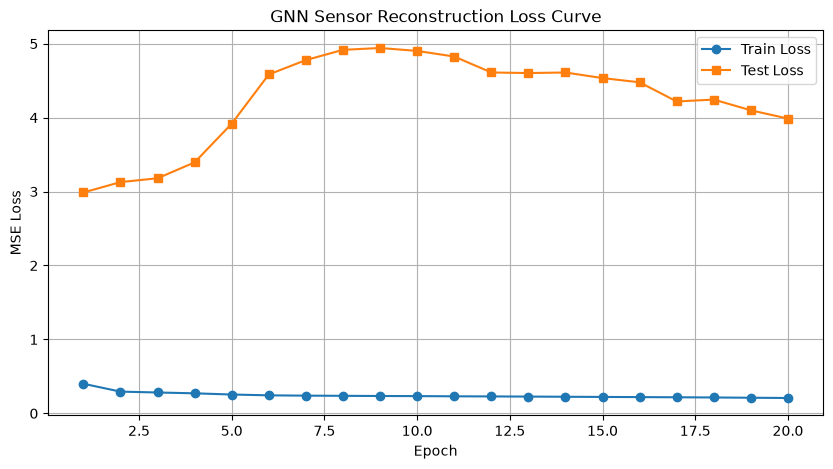

In [12]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))
plt.plot(range(1, num_epochs + 1), train_losses, label="Train Loss", marker="o")
plt.plot(range(1, num_epochs + 1), test_losses, label="Test Loss", marker="s")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("GNN Sensor Reconstruction Loss Curve")
plt.legend()
plt.grid(True)
plt.show()
